# Breast Cancer Classification - ML Assignment 2

The UCI Breast Cancer Wisconsin (Diagnostic) dataset: 569 instances, 30 numeric features, and two target classes. The original public source is https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic.

The project consistently uses Malignant = 1 as the positive class and Benign = 0. It performs a stratified 80/20 split with random_state=42. Run cells in order; the final cells create all GitHub and Streamlit files in the current project folder.

In [1]:
from pathlib import Path
from textwrap import dedent
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    matthews_corrcoef, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd().resolve()
DATA_DIR, MODEL_DIR, RESULTS_DIR = PROJECT_ROOT / "data", PROJECT_ROOT / "models", PROJECT_ROOT / "results"
FIGURE_DIR = RESULTS_DIR / "figures"
for directory in (DATA_DIR, MODEL_DIR, RESULTS_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)

Project root: /content


## Dataset loading and basic EDA

Scikit-learn originally records 0 as malignant and 1 as benign. The target is reversed below so that all metrics treat malignant cases as the positive class. The assertions guard against a changed, incomplete, or unexpected dataset before modelling begins.

Feature shape: (569, 30)
Missing values: 0


,Diagnosis,Encoded value
0,Malignant,1
1,Benign,0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


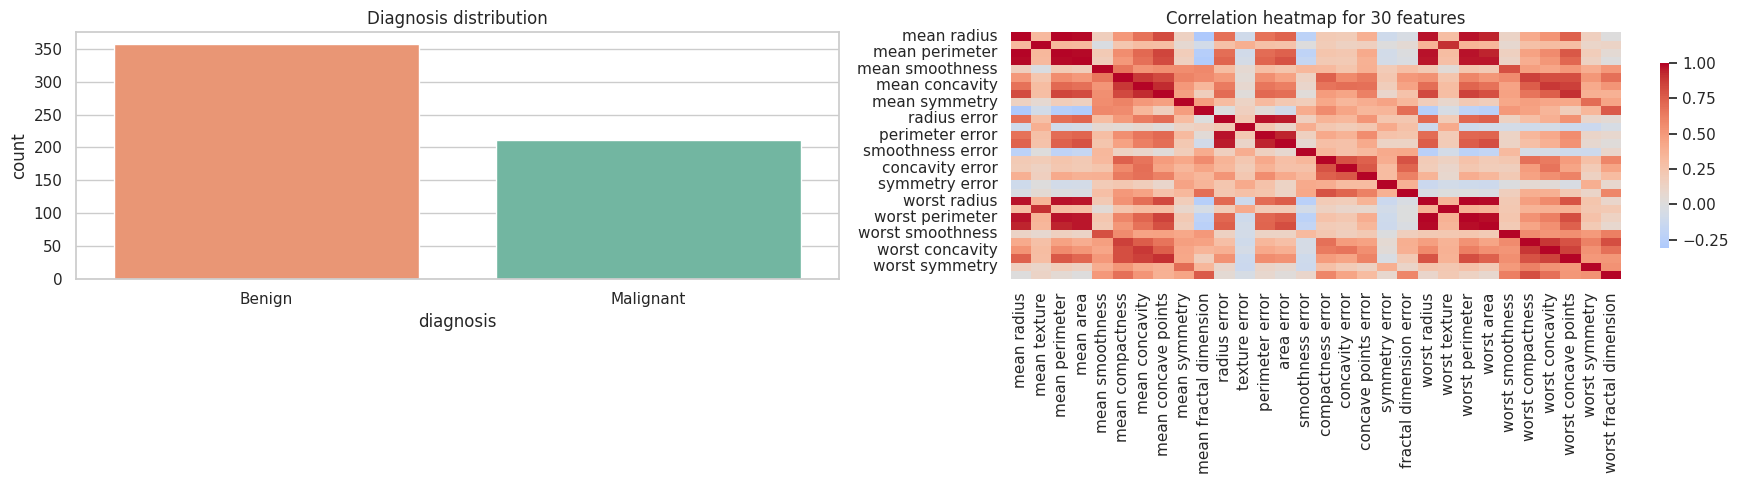

Saved original dataset CSV: /content/data/breast_cancer_wisconsin_diagnostic.csv


In [2]:
cancer = load_breast_cancer(as_frame=True)
X = cancer.data.copy()
y = (cancer.target == 0).astype(int).rename("target")  # Malignant=1, Benign=0
diagnosis = y.map({1: "Malignant", 0: "Benign"})

dataset = X.copy()
dataset["diagnosis"] = diagnosis
assert X.shape == (569, 30), f"Expected 569 rows and 30 features, found {X.shape}."
assert set(y.unique()) == {0, 1}
assert dataset.isna().sum().sum() == 0
assert (y == 1).sum() == 212 and (y == 0).sum() == 357

DATASET_PATH = DATA_DIR / "breast_cancer_wisconsin_diagnostic.csv"
dataset.to_csv(DATASET_PATH, index=False)
print("Feature shape:", X.shape)
print("Missing values:", dataset.isna().sum().sum())
display(pd.DataFrame({"Diagnosis": ["Malignant", "Benign"], "Encoded value": [1, 0]}))
display(X.describe().T)

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sns.countplot(data=dataset, x="diagnosis", order=["Benign", "Malignant"],
              hue="diagnosis", legend=False, palette="Set2", ax=axes[0])
axes[0].set_title("Diagnosis distribution")
sns.heatmap(X.corr(), cmap="coolwarm", center=0, ax=axes[1], cbar_kws={"shrink": .75})
axes[1].set_title("Correlation heatmap for 30 features")
plt.tight_layout()
EDA_PATH = FIGURE_DIR / "eda_overview.png"
plt.savefig(EDA_PATH, dpi=150, bbox_inches="tight")
plt.show()
print("Saved original dataset CSV:", DATASET_PATH)

## Stratified train/test split and models

The exported test_data.csv has all 30 features plus diagnosis. It is held out during training and is the file used for testing the Streamlit app. Scaling is inside each appropriate pipeline, which prevents a scaler from learning from held-out data.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.20, random_state=RANDOM_STATE, stratify=y
)
test_data = X_test.copy()
test_data["diagnosis"] = y_test.map({1: "Malignant", 0: "Benign"})
TEST_PATH = PROJECT_ROOT / "test_data.csv"
test_data.to_csv(TEST_PATH, index=False)
assert test_data.shape == (114, 31)
print("Train/test:", X_train.shape, X_test.shape)
print("Saved held-out test CSV:", TEST_PATH)

models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("classifier", LogisticRegression(max_iter=5000, random_state=42))]),
    "Decision Tree": Pipeline([("classifier", DecisionTreeClassifier(max_depth=5, min_samples_split=5, random_state=42))]),
    "KNN": Pipeline([("scaler", StandardScaler()), ("classifier", KNeighborsClassifier(n_neighbors=5))]),
    "Gaussian Naive Bayes": Pipeline([("scaler", StandardScaler()), ("classifier", GaussianNB())]),
    "RBF SVM": Pipeline([("scaler", StandardScaler()),
                         ("classifier", SVC(kernel="rbf", C=1.0, probability=True, random_state=42))]),
}
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "gaussian_naive_bayes.joblib",
    "RBF SVM": "rbf_svm.joblib",
}

Train/test: (455, 30) (114, 30)
Saved held-out test CSV: /content/test_data.csv


## Train, measure, and save all five pipelines

The six required metrics are calculated on only the held-out test set. ROC-AUC is based on malignant probabilities; the other metrics use predicted classes. Every saved joblib file includes the preprocessing pipeline and classifier together.

In [4]:
rows, predictions, probabilities, reports = [], {}, {}, {}
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    predicted = pipeline.predict(X_test)
    positive_index = list(pipeline.classes_).index(1)
    probability = pipeline.predict_proba(X_test)[:, positive_index]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "ROC-AUC": roc_auc_score(y_test, probability),
        "Precision": precision_score(y_test, predicted, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, predicted, pos_label=1, zero_division=0),
        "F1": f1_score(y_test, predicted, pos_label=1, zero_division=0),
        "MCC": matthews_corrcoef(y_test, predicted),
    })
    predictions[name], probabilities[name] = predicted, probability
    reports[name] = classification_report(y_test, predicted, target_names=["Benign (0)", "Malignant (1)"], zero_division=0)
    joblib.dump(pipeline, MODEL_DIR / model_files[name])

comparison = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
COMPARISON_PATH = RESULTS_DIR / "model_comparison.csv"
comparison.to_csv(COMPARISON_PATH, index=False)
display(comparison.style.format({col: "{:.4f}" for col in comparison.columns if col != "Model"}))
print("Saved five pipelines in:", MODEL_DIR)
print("Saved comparison CSV:", COMPARISON_PATH)

,Model,Accuracy,ROC-AUC,Precision,Recall,F1,MCC
0,RBF SVM,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442
1,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Gaussian Naive Bayes,0.9211,0.9891,0.9231,0.8571,0.8889,0.8292
4,Decision Tree,0.9211,0.9676,0.9459,0.8333,0.8861,0.8299


Saved five pipelines in: /content/models
Saved comparison CSV: /content/results/model_comparison.csv


## Confusion matrices, ROC curves, classification reports, and observations

A false negative is a malignant sample predicted as benign, therefore malignant recall should be discussed alongside accuracy. MCC incorporates all four parts of a confusion matrix and is particularly useful for unequal class counts.

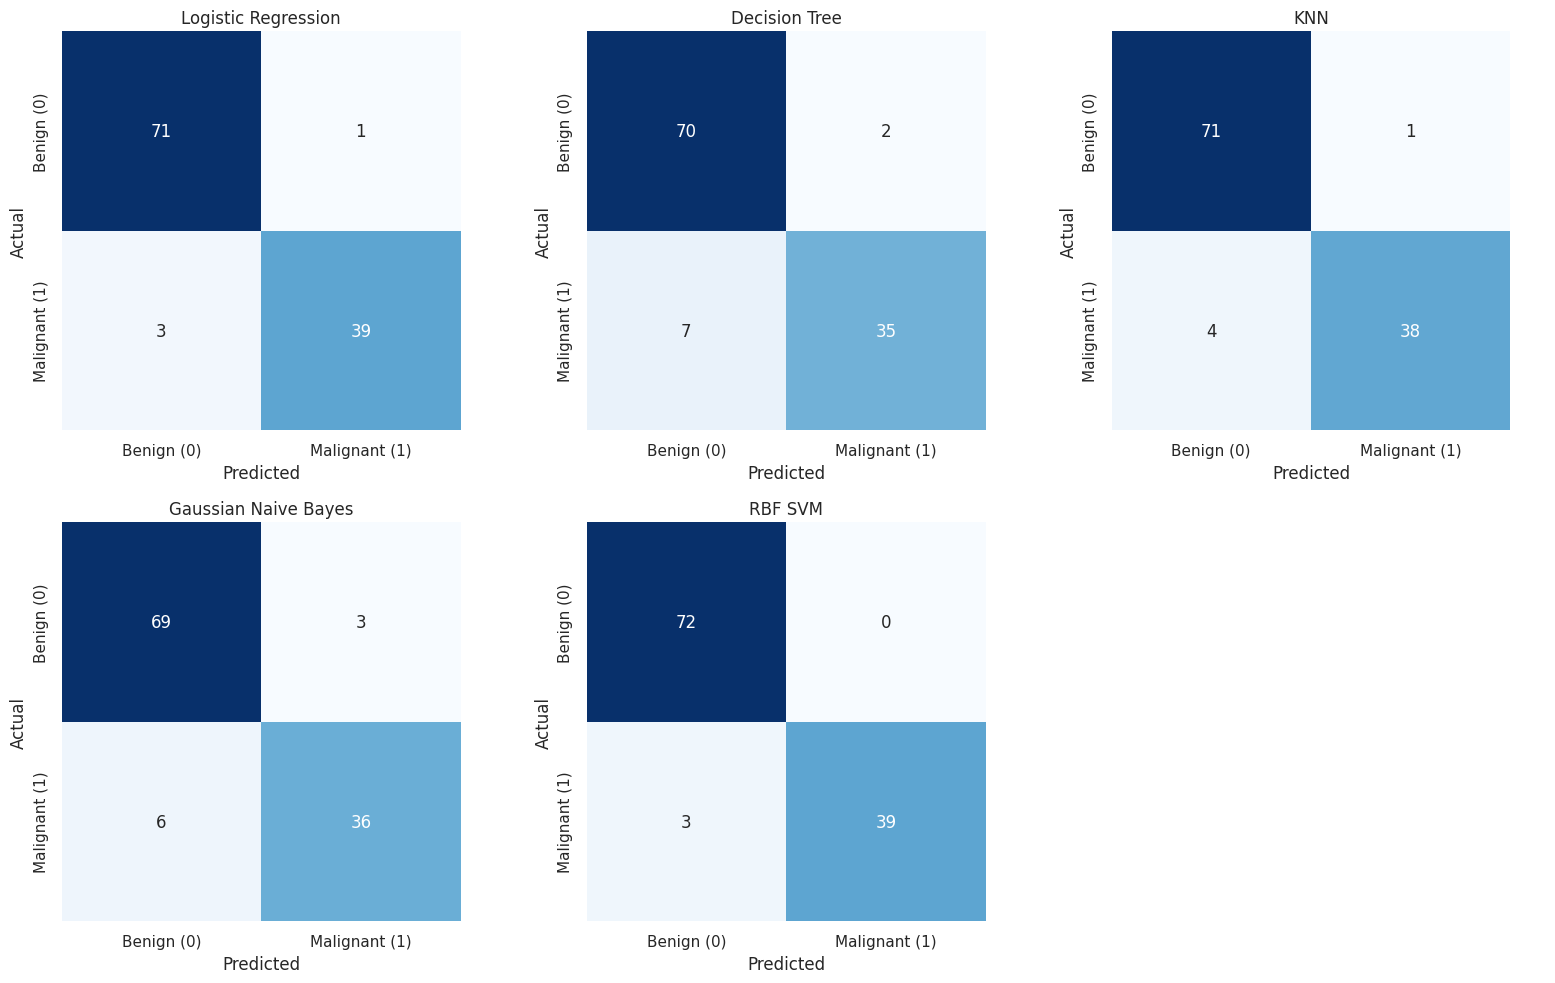

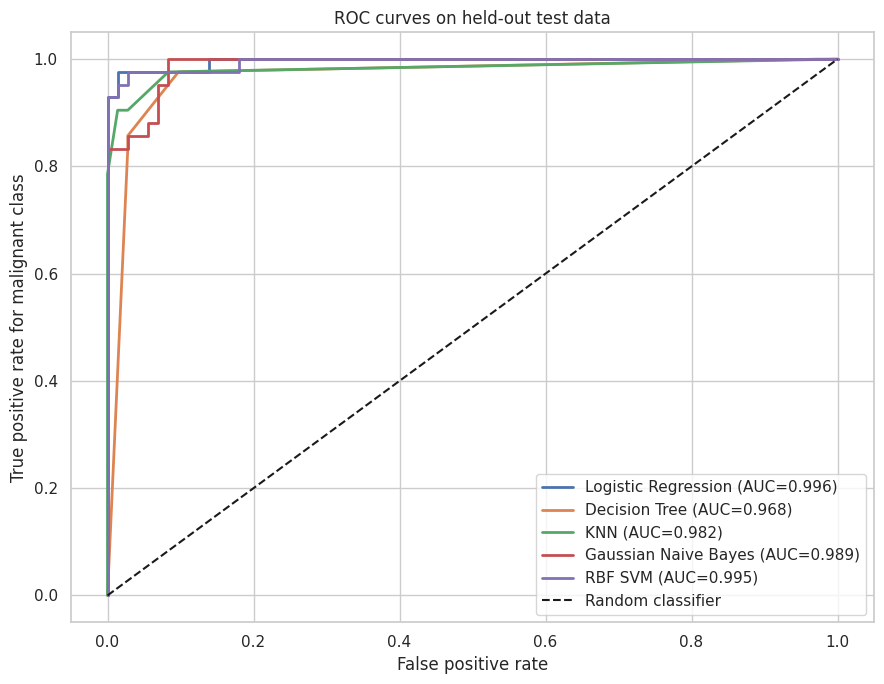

RBF SVM: Accuracy=0.974, ROC-AUC=0.995, Precision=1.000, Recall=0.929, F1=0.963, MCC=0.944. Results are from the same held-out test set.

Logistic Regression: Accuracy=0.965, ROC-AUC=0.996, Precision=0.975, Recall=0.929, F1=0.951, MCC=0.925. Results are from the same held-out test set.

KNN: Accuracy=0.956, ROC-AUC=0.982, Precision=0.974, Recall=0.905, F1=0.938, MCC=0.906. Results are from the same held-out test set.

Gaussian Naive Bayes: Accuracy=0.921, ROC-AUC=0.989, Precision=0.923, Recall=0.857, F1=0.889, MCC=0.829. Results are from the same held-out test set.

Decision Tree: Accuracy=0.921, ROC-AUC=0.968, Precision=0.946, Recall=0.833, F1=0.886, MCC=0.830. Results are from the same held-out test set.

Overall winner by malignant-class F1: RBF SVM (0.963). This result is for the fixed held-out split; a larger study should use cross-validation.

Recall measures malignant cases detected. MCC uses all four confusion-matrix cells and complements accuracy.


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for axis, name in zip(axes.ravel(), models):
    matrix = confusion_matrix(y_test, predictions[name], labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                xticklabels=["Benign (0)", "Malignant (1)"],
                yticklabels=["Benign (0)", "Malignant (1)"], ax=axis)
    axis.set_title(name)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")
axes.ravel()[-1].axis("off")
plt.tight_layout()
CM_PATH = FIGURE_DIR / "confusion_matrices.png"
plt.savefig(CM_PATH, dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(9, 7))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name], pos_label=1)
    auc = comparison.loc[comparison["Model"] == name, "ROC-AUC"].iloc[0]
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate for malignant class")
plt.title("ROC curves on held-out test data"); plt.legend(loc="lower right"); plt.tight_layout()
ROC_PATH = FIGURE_DIR / "roc_curves.png"
plt.savefig(ROC_PATH, dpi=150, bbox_inches="tight")
plt.show()

REPORT_PATH = RESULTS_DIR / "classification_reports.txt"
REPORT_PATH.write_text("\n".join(f"{'=' * 70}\n{name}\n{'=' * 70}\n{report}\n" for name, report in reports.items()))
winner = comparison.iloc[0]
observations = [
    f"{row['Model']}: Accuracy={row['Accuracy']:.3f}, ROC-AUC={row['ROC-AUC']:.3f}, Precision={row['Precision']:.3f}, Recall={row['Recall']:.3f}, F1={row['F1']:.3f}, MCC={row['MCC']:.3f}. Results are from the same held-out test set."
    for _, row in comparison.iterrows()
]
observations.append(f"Overall winner by malignant-class F1: {winner['Model']} ({winner['F1']:.3f}). This result is for the fixed held-out split; a larger study should use cross-validation.")
observations.append("Recall measures malignant cases detected. MCC uses all four confusion-matrix cells and complements accuracy.")
OBSERVATIONS_PATH = RESULTS_DIR / "observations.txt"
OBSERVATIONS_PATH.write_text("\n\n".join(observations))
print(OBSERVATIONS_PATH.read_text())

In [7]:
requirements = """pandas>=2.0
numpy>=1.24
scikit-learn>=1.3
matplotlib>=3.7
seaborn>=0.12
joblib>=1.3
streamlit>=1.35
"""

train_script = r"""from pathlib import Path
import joblib, pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, matthews_corrcoef
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

ROOT = Path(__file__).resolve().parent
DATA, MODELS, RESULTS = ROOT / "data", ROOT / "models", ROOT / "results"
for folder in (DATA, MODELS, RESULTS): folder.mkdir(exist_ok=True)
cancer = load_breast_cancer(as_frame=True)
X = cancer.data.copy()
y = (cancer.target == 0).astype(int)  # Malignant=1, Benign=0
assert X.shape == (569, 30) and y.nunique() == 2
full = X.copy(); full["diagnosis"] = y.map({1: "Malignant", 0: "Benign"})
full.to_csv(DATA / "breast_cancer_wisconsin_diagnostic.csv", index=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=42, stratify=y)
held_out = X_test.copy(); held_out["diagnosis"] = y_test.map({1: "Malignant", 0: "Benign"})
held_out.to_csv(ROOT / "test_data.csv", index=False)
models = {
 "Logistic Regression": Pipeline([("scaler", StandardScaler()),("classifier", LogisticRegression(max_iter=5000, random_state=42))]),
 "Decision Tree": Pipeline([("classifier", DecisionTreeClassifier(max_depth=5, min_samples_split=5, random_state=42))]),
 "KNN": Pipeline([("scaler", StandardScaler()),("classifier", KNeighborsClassifier(n_neighbors=5))]),
 "Gaussian Naive Bayes": Pipeline([("scaler", StandardScaler()),("classifier", GaussianNB())]),
 "RBF SVM": Pipeline([("scaler", StandardScaler()),("classifier", SVC(kernel="rbf", C=1.0, probability=True, random_state=42))]),
}
names = dict(zip(models, ["logistic_regression.joblib", "decision_tree.joblib", "knn.joblib", "gaussian_naive_bayes.joblib", "rbf_svm.joblib"]))
rows = []
for name, pipeline in models.items():
 pipeline.fit(X_train, y_train); pred = pipeline.predict(X_test)
 prob = pipeline.predict_proba(X_test)[:, list(pipeline.classes_).index(1)]
 rows.append({"Model": name, "Accuracy": accuracy_score(y_test,pred), "ROC-AUC": roc_auc_score(y_test,prob), "Precision": precision_score(y_test,pred,zero_division=0), "Recall": recall_score(y_test,pred,zero_division=0), "F1": f1_score(y_test,pred,zero_division=0), "MCC": matthews_corrcoef(y_test,pred)})
 joblib.dump(pipeline, MODELS / names[name])
comparison = pd.DataFrame(rows).sort_values("F1", ascending=False)
comparison.to_csv(RESULTS / "model_comparison.csv", index=False)
print(comparison.to_string(index=False))
"""

app_script = r"""from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import streamlit as st
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

ROOT = Path(__file__).resolve().parent
MODEL_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"

MODEL_OPTIONS = {
    "Logistic Regression": {
        "file": "logistic_regression.joblib",
        "type": "Linear baseline",
        "description": "A transparent linear classifier after feature scaling.",
    },
    "Decision Tree": {
        "file": "decision_tree.joblib",
        "type": "Rule-based model",
        "description": "Learns decision rules from the feature values.",
    },
    "KNN": {
        "file": "knn.joblib",
        "type": "Neighbour voting",
        "description": "Predicts from nearby samples in scaled feature space.",
    },
    "Gaussian Naive Bayes": {
        "file": "gaussian_naive_bayes.joblib",
        "type": "Probability model",
        "description": "Uses Gaussian probability assumptions for the features.",
    },
    "RBF SVM": {
        "file": "rbf_svm.joblib",
        "type": "Non-linear boundary",
        "description": "Uses an RBF kernel for non-linear classification.",
    },
}

st.set_page_config(
    page_title="Breast Cancer Analysis",
    page_icon="◈",
    layout="wide",
    initial_sidebar_state="expanded",
)

st.markdown(
    '''
    <style>
        .stApp {
            background:
                radial-gradient(circle at 88% 8%, #e9dfff 0, transparent 24rem),
                radial-gradient(circle at 4% 14%, #dcd0ff 0, transparent 19rem),
                linear-gradient(135deg, #fbfaff 0%, #f0edff 100%);
        }

        [data-testid="stSidebar"] {
            background: linear-gradient(180deg, #170b30 0%, #2a1452 55%, #45216d 100%);
        }

        [data-testid="stSidebar"] h1,
        [data-testid="stSidebar"] h2,
        [data-testid="stSidebar"] h3,
        [data-testid="stSidebar"] p,
        [data-testid="stSidebar"] label,
        [data-testid="stSidebar"] span {
            color: #ffffff !important;
        }

        .hero {
            background: linear-gradient(
                115deg,
                rgba(26, 9, 56, .93) 0%,
                rgba(73, 35, 126, .78) 58%,
                rgba(129, 87, 185, .65) 100%
            );
            backdrop-filter: blur(18px);
            -webkit-backdrop-filter: blur(18px);
            border: 1px solid rgba(255, 255, 255, .38);
            border-radius: 22px;
            box-shadow: 0 15px 36px rgba(45, 18, 85, .28);
            color: white;
            margin-bottom: 1.2rem;
            padding: 2rem 2.25rem;
        }

        .hero h1 {
            color: white;
            font-size: 2.2rem;
            letter-spacing: -.04em;
            margin: 0;
        }

        .hero p {
            color: #eee8ff;
            margin: .5rem 0 0;
        }

        .eyebrow {
            color: #dccaff;
            font-size: .75rem;
            font-weight: 700;
            letter-spacing: .13em;
        }

        .model-pill {
            background: rgba(235, 221, 255, .95);
            border-radius: 999px;
            color: #431b72;
            display: inline-block;
            font-size: .82rem;
            font-weight: 700;
            padding: .32rem .72rem;
        }

        .section-note {
            background: rgba(255, 255, 255, .63);
            backdrop-filter: blur(12px);
            border: 1px solid rgba(116, 75, 174, .24);
            border-left: 4px solid #7042ad;
            border-radius: 0 11px 11px 0;
            color: #352051;
            margin-bottom: 1rem;
            padding: .8rem 1rem;
        }

        [data-testid="stMetric"] {
            background: rgba(255, 255, 255, .68);
            backdrop-filter: blur(14px);
            border: 1px solid rgba(116, 75, 174, .20);
            border-radius: 14px;
            box-shadow: 0 5px 16px rgba(47, 21, 86, .08);
            padding: .8rem;
        }

        [data-baseweb="select"] > div {
            background: #ffffff !important;
            border: 1px solid #bda4e5 !important;
            box-shadow: 0 4px 12px rgba(31, 9, 63, .20);
        }

        [data-baseweb="select"] * {
            color: #2d1454 !important;
        }

        ul[data-baseweb="menu"] {
            background: #ffffff !important;
        }

        ul[data-baseweb="menu"] li {
            color: #2d1454 !important;
        }

        div[data-testid="stFileUploader"] {
            background: rgba(255, 255, 255, .72);
            border: 1px dashed #8a65bc;
            border-radius: 13px;
            padding: .55rem;
        }

        div[data-testid="stFileUploader"] button,
        .stDownloadButton > button {
            background: linear-gradient(100deg, #4c207e 0%, #7042ad 100%) !important;
            border: 1px solid rgba(255, 255, 255, .55) !important;
            border-radius: 9px !important;
            box-shadow: 0 5px 12px rgba(69, 29, 113, .22);
            color: #ffffff !important;
            font-weight: 700 !important;
        }

        div[data-testid="stFileUploader"] button:hover,
        .stDownloadButton > button:hover {
            background: linear-gradient(100deg, #35145e 0%, #5b3194 100%) !important;
            color: #ffffff !important;
        }

        .stTabs [data-baseweb="tab"] {
            color: #4b2878;
            font-weight: 700;
        }

        .stTabs [aria-selected="true"] {
            border-bottom-color: #63389d !important;
            color: #2e105b !important;
        }
    </style>
    ''',
    unsafe_allow_html=True,
)


@st.cache_resource(show_spinner=False)
def load_model(model_path):
    return joblib.load(model_path)


@st.cache_data(show_spinner=False)
def load_csv(file_or_path):
    return pd.read_csv(file_or_path)


def encode_diagnosis(series):
    if pd.api.types.is_numeric_dtype(series):
        encoded = pd.to_numeric(series, errors="coerce")
    else:
        encoded = (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "malignant": 1,
                "benign": 0,
                "m": 1,
                "b": 0,
                "1": 1,
                "0": 0,
            })
        )

    if encoded.isna().any() or not set(encoded.unique()).issubset({0, 1}):
        raise ValueError("Diagnosis values must be Malignant/Benign, M/B, or 1/0.")

    return encoded.astype(int)


def get_metrics(y_true, y_pred, probability):
    auc_value = roc_auc_score(y_true, probability) if y_true.nunique() == 2 else None

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "ROC-AUC": auc_value,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }


with st.sidebar:
    st.markdown("## ◈ Breast Cancer")
    st.caption("Analysis dashboard")
    st.divider()

    selected_model = st.selectbox(
        "Select a classifier",
        list(MODEL_OPTIONS.keys()),
    )

    st.markdown(
        f"<span class='model-pill'>{MODEL_OPTIONS[selected_model]['type']}</span>",
        unsafe_allow_html=True,
    )
    st.caption(MODEL_OPTIONS[selected_model]["description"])

    st.divider()

    threshold = st.slider(
        "Malignant probability threshold",
        min_value=0.10,
        max_value=0.90,
        value=0.50,
        step=0.01,
        help="A probability at or above this value is labelled Malignant.",
    )

    st.caption("Target: Malignant = 1 · Benign = 0")


st.markdown(
    '''
    <div class="hero">
        <div class="eyebrow">INTERACTIVE MACHINE LEARNING DASHBOARD</div>
        <h1>Breast Cancer Analysis</h1>
        <p>Evaluate saved machine-learning classifiers using held-out diagnostic data.</p>
    </div>
    ''',
    unsafe_allow_html=True,
)

evaluate_tab, guide_tab, compare_tab = st.tabs(
    ["Evaluate model", "Dataset guide", "Model comparison"]
)

with evaluate_tab:
    st.markdown(
        '''
        <div class="section-note">
            Upload the generated <b>test_data.csv</b>. It must contain all 30 input features
            and the <b>diagnosis</b> target column.
        </div>
        ''',
        unsafe_allow_html=True,
    )

    included_test_file = ROOT / "test_data.csv"

    source_type = st.radio(
        "Choose test data source",
        ["Upload a CSV", "Use included test_data.csv"],
        horizontal=True,
        disabled=not included_test_file.exists(),
    )

    uploaded_file = None

    if source_type == "Upload a CSV":
        uploaded_file = st.file_uploader(
            "Upload held-out test CSV",
            type=["csv"],
        )

    test_df = None

    if source_type == "Use included test_data.csv" and included_test_file.exists():
        test_df = load_csv(included_test_file)

    elif uploaded_file is not None:
        test_df = load_csv(uploaded_file)

    if test_df is None:
        st.info("Select a data source and provide a CSV to begin evaluation.")

    else:
        model_path = MODEL_DIR / MODEL_OPTIONS[selected_model]["file"]

        if not model_path.exists():
            st.error(
                f"Saved model file not found: {model_path.name}. "
                "Run the notebook or train_models.py first."
            )
            st.stop()

        if "diagnosis" not in test_df.columns:
            st.error("The CSV must contain a diagnosis column.")
            st.stop()

        model = load_model(str(model_path))
        X_test = test_df.drop(columns=["diagnosis"])

        expected_features = list(getattr(model, "feature_names_in_", X_test.columns))
        missing_features = sorted(set(expected_features) - set(X_test.columns))
        extra_features = sorted(set(X_test.columns) - set(expected_features))

        if missing_features or extra_features:
            st.error(
                f"Feature mismatch. Missing: {missing_features or 'none'} | "
                f"Extra: {extra_features or 'none'}"
            )
            st.stop()

        try:
            y_true = encode_diagnosis(test_df["diagnosis"])
        except ValueError as error:
            st.error(str(error))
            st.stop()

        X_test = X_test[expected_features]

        probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
        y_pred = (probability >= threshold).astype(int)

        metrics = get_metrics(y_true, y_pred, probability)

        preview_column, summary_column = st.columns([2.2, 1])

        with preview_column:
            st.markdown("#### Uploaded data preview")
            st.dataframe(test_df.head(8), use_container_width=True, height=260)

        with summary_column:
            st.markdown("#### Data summary")
            st.metric("Test rows", len(test_df))
            st.metric("Features checked", len(expected_features))
            st.metric("Malignant cases", f"{y_true.mean() * 100:.1f}%")

        st.markdown("#### Evaluation metrics")

        metric_columns = st.columns(6)

        for column, (label, value) in zip(metric_columns, metrics.items()):
            column.metric(label, "—" if value is None else f"{value:.4f}")

        left_column, right_column = st.columns(2)

        with left_column:
            st.markdown("#### Confusion matrix")

            matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])

            figure, axis = plt.subplots(figsize=(5.2, 4.3))

            sns.heatmap(
                matrix,
                annot=True,
                fmt="d",
                cmap="Purples",
                cbar=False,
                square=True,
                linewidths=.5,
                linecolor="white",
                xticklabels=["Benign", "Malignant"],
                yticklabels=["Benign", "Malignant"],
                ax=axis,
            )

            axis.set_xlabel("Predicted diagnosis")
            axis.set_ylabel("Actual diagnosis")

            st.pyplot(figure, use_container_width=True)
            plt.close(figure)

        with right_column:
            st.markdown("#### ROC curve")

            figure, axis = plt.subplots(figsize=(5.2, 4.3))

            if y_true.nunique() == 2:
                false_positive_rate, true_positive_rate, _ = roc_curve(
                    y_true,
                    probability,
                    pos_label=1,
                )

                axis.plot(
                    false_positive_rate,
                    true_positive_rate,
                    color="#63389d",
                    linewidth=2.8,
                    label=f"AUC = {metrics['ROC-AUC']:.3f}",
                )

                axis.plot(
                    [0, 1],
                    [0, 1],
                    "--",
                    color="#aa98bf",
                    label="Random baseline",
                )

                axis.legend(loc="lower right", frameon=False)

            else:
                axis.text(
                    .5,
                    .5,
                    "ROC curve needs both classes.",
                    ha="center",
                    va="center",
                )

            axis.set_xlabel("False positive rate")
            axis.set_ylabel("True positive rate")
            axis.set_title("Probability performance")

            st.pyplot(figure, use_container_width=True)
            plt.close(figure)

        report_column, download_column = st.columns([1.4, 1])

        with report_column:
            st.markdown("#### Classification report")

            st.code(
                classification_report(
                    y_true,
                    y_pred,
                    target_names=["Benign (0)", "Malignant (1)"],
                    zero_division=0,
                )
            )

        with download_column:
            st.markdown("#### Download predictions")

            prediction_export = test_df.copy()
            prediction_export["malignant_probability"] = probability.round(6)
            prediction_export["predicted_diagnosis"] = pd.Series(y_pred).map(
                {0: "Benign", 1: "Malignant"}
            )

            st.download_button(
                "Download evaluated CSV",
                data=prediction_export.to_csv(index=False).encode("utf-8"),
                file_name=f"evaluated_{selected_model.lower().replace(' ', '_')}.csv",
                mime="text/csv",
            )

            st.caption(
                "The downloaded file includes probabilities and predictions "
                "at the selected threshold."
            )

with guide_tab:
    st.subheader("Dataset and metric guide")

    st.markdown(
    '''
    - **Dataset:** 569 samples with 30 numerical diagnostic features.
    - **Positive class:** Malignant = 1, so recall means the fraction of malignant cases detected.
    - **ROC-AUC:** Measures probability ranking quality across decision thresholds.
    - **MCC:** Uses all four confusion-matrix values and complements accuracy.
    - **Threshold slider:** Lets you explore the precision and recall trade-off without retraining.
    '''
)

    feature_guide = pd.DataFrame(
        {
            "Feature": [
                "mean radius",
                "mean texture",
                "mean perimeter",
                "mean area",
                "mean smoothness",
            ],
            "Description": [
                "Average distance from the cell centre to boundary points.",
                "Variation in grayscale values of the image.",
                "Average tumour boundary length.",
                "Average area enclosed by the tumour boundary.",
                "Local variation in radius lengths.",
            ],
        }
    )

    st.dataframe(feature_guide, use_container_width=True, hide_index=True)

with compare_tab:
    comparison_path = RESULTS_DIR / "model_comparison.csv"

    if comparison_path.exists():
        comparison = load_csv(comparison_path)

        st.subheader("Five-model comparison")
        st.caption("These values were generated by the notebook on the held-out test set.")

        st.dataframe(comparison.round(4), use_container_width=True, hide_index=True)

        selected_metric = st.selectbox(
            "Rank the five models by",
            ["F1", "Recall", "ROC-AUC", "MCC", "Accuracy", "Precision"],
        )

        ranking = comparison.sort_values(selected_metric, ascending=False)

        figure, axis = plt.subplots(figsize=(8.5, 4.2))

        sns.barplot(
            data=ranking,
            x=selected_metric,
            y="Model",
            palette="Purples",
            ax=axis,
        )

        axis.set_title(f"Model ranking by {selected_metric}")
        axis.set_xlim(0, max(1.0, ranking[selected_metric].max() + .05))

        for container in axis.containers:
            axis.bar_label(container, fmt="%.3f", padding=4)

        st.pyplot(figure, use_container_width=True)
        plt.close(figure)

    else:
        st.info("Run the notebook first to create results/model_comparison.csv.")
"""

metric_cols = ["Accuracy", "ROC-AUC", "Precision", "Recall", "F1", "MCC"]
table_header = "| Model | " + " | ".join(metric_cols) + " |"
table_rule = "|---|" + "|".join(["---:"] * len(metric_cols)) + "|"
table_rows = "\n".join("| " + r["Model"] + " | " + " | ".join(f"{r[c]:.4f}" for c in metric_cols) + " |" for _, r in comparison.iterrows())
readme = f"""# Breast Cancer Classification — ML Assignment 2

## a. Problem statement
This project compares five classifiers for predicting whether a breast-cancer sample is malignant or benign. The Streamlit app evaluates uploaded test data using saved pipelines; it does not retrain a model.

## b. Dataset description
The Breast Cancer Wisconsin (Diagnostic) dataset is bundled with scikit-learn and attributed to the UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic. It has 569 instances, 30 numerical inputs, 212 malignant and 357 benign cases, with no missing data. This project uses Malignant = 1 and Benign = 0, with a stratified 80/20 split and random_state=42.

## c. GitHub repository link
Replace after publishing: https://github.com/your-username/your-repository-name

## d. Models used and comparison
Models: Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, and RBF SVM. Preprocessing is inside relevant pipelines to avoid test-data leakage.

{table_header}
{table_rule}
{table_rows}

All values are from the held-out test set and saved in results/model_comparison.csv.

## Observations
{chr(10).join("- " + observation for observation in observations)}

## Run locally
1. Install packages with pip install -r requirements.txt.
2. Run python train_models.py.
3. Run streamlit run app.py.
4. Upload test_data.csv, choose a model, and inspect six metrics, a confusion matrix, ROC curve, and classification report.

## Repository contents
Notebook, train_models.py, app.py, requirements.txt, README.md, test_data.csv, data/breast_cancer_wisconsin_diagnostic.csv, five model files, and results files are included.
"""

(PROJECT_ROOT / "requirements.txt").write_text(requirements)
(PROJECT_ROOT / "train_models.py").write_text(train_script)
(PROJECT_ROOT / "app.py").write_text(app_script)
(PROJECT_ROOT / "README.md").write_text(readme)
print("Created requirements.txt, train_models.py, app.py, and README.md")

Created requirements.txt, train_models.py, app.py, and README.md
